In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.shape

(768, 9)

In [4]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [5]:
df = df.dropna(subset=["Outcome"]).copy()
feature_cols = df.columns.drop("Outcome")
missing_feature_cols = df[feature_cols].select_dtypes(include="number").columns[df[feature_cols].select_dtypes(include="number").isnull().any()]
for col in missing_feature_cols:
    df[col] = df[col].fillna(df[col].median())

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [8]:
df.duplicated().sum()

np.int64(0)

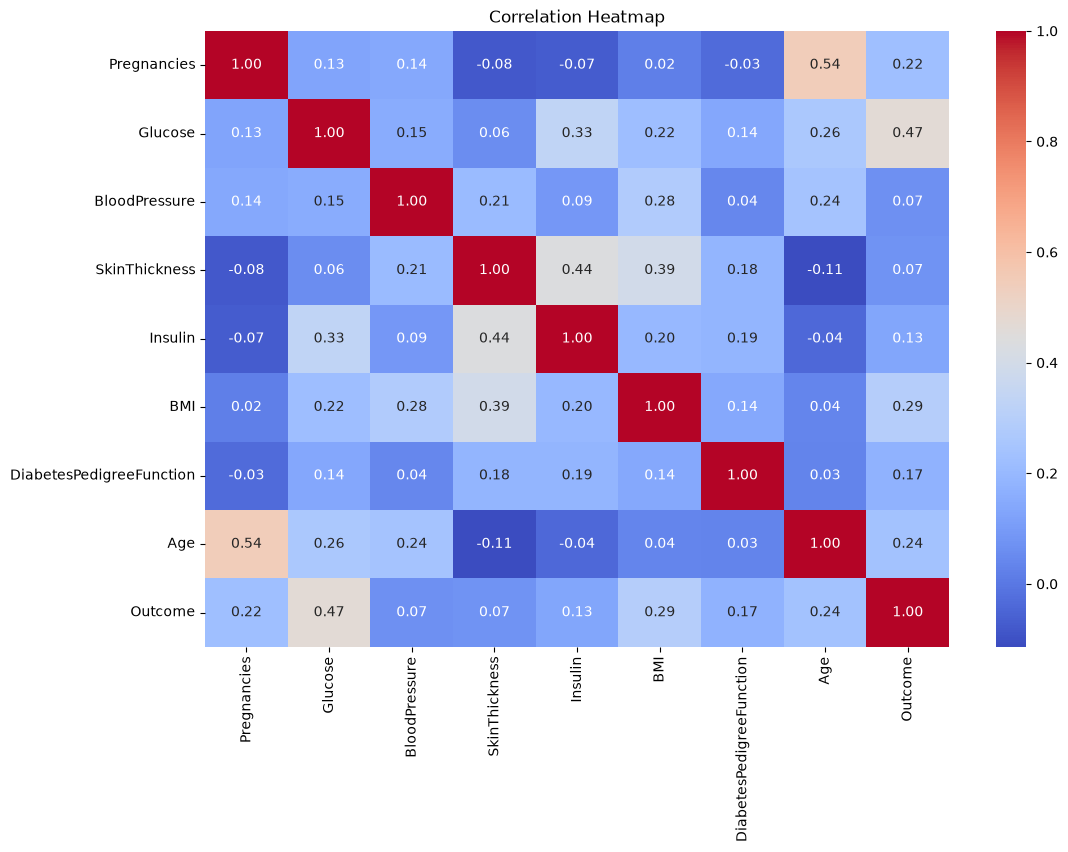

In [9]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

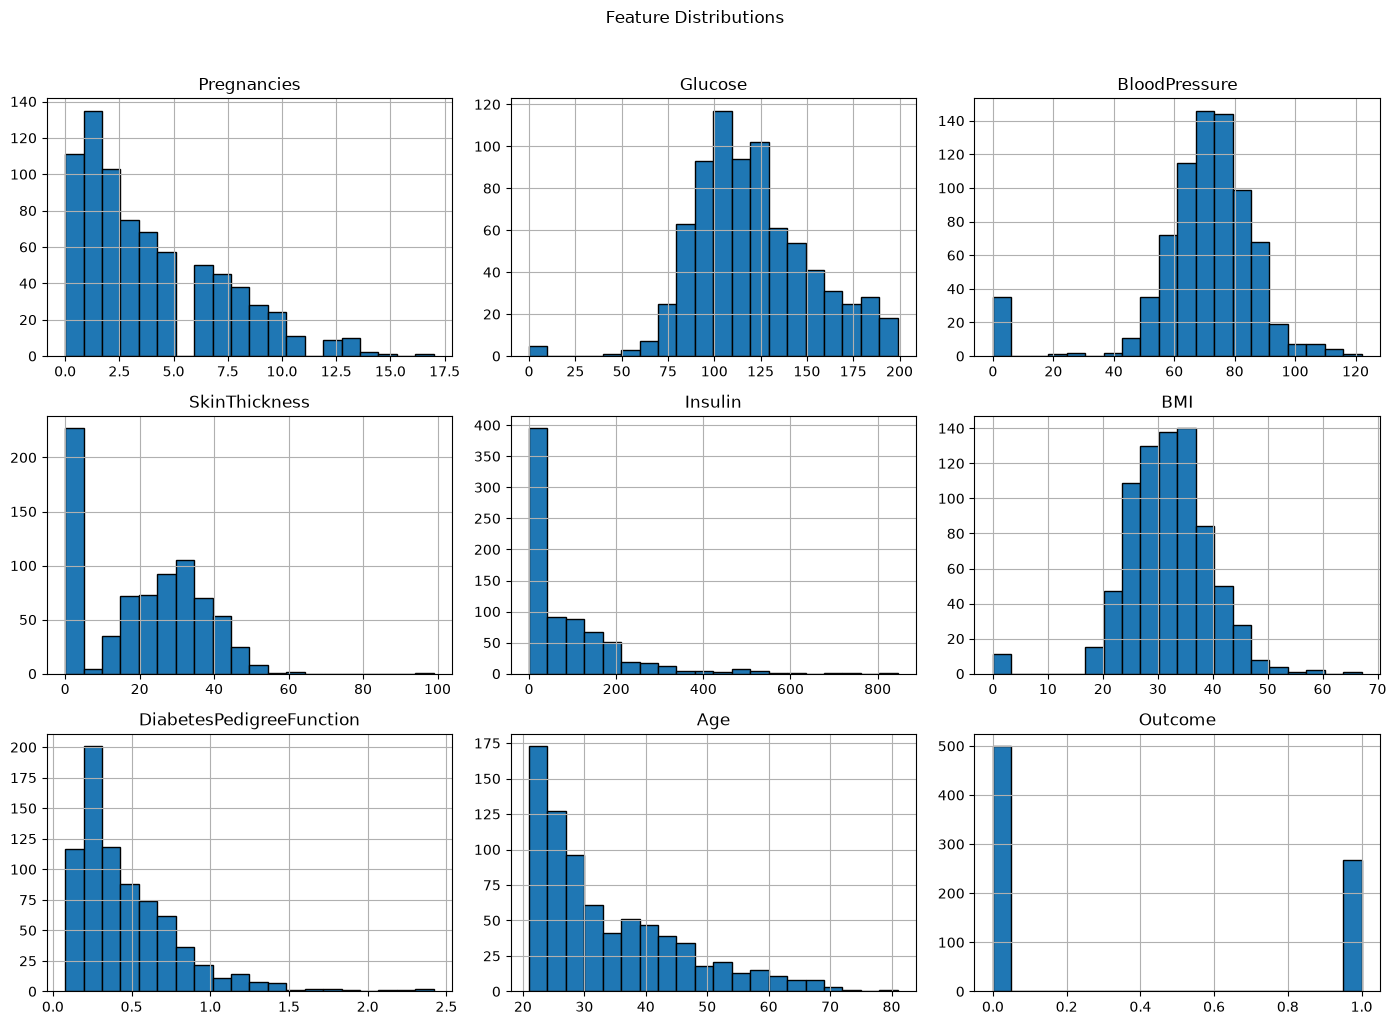

In [10]:
df.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

In [11]:
# Cap numeric outliers using the IQR method
for col in df.select_dtypes(include="number").columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    df[col] = df[col].clip(lower, upper)

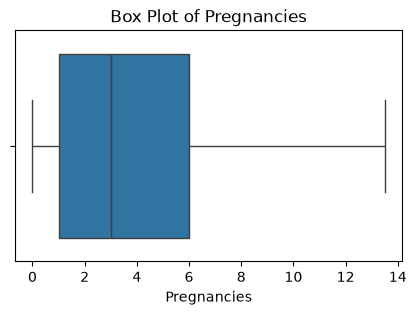

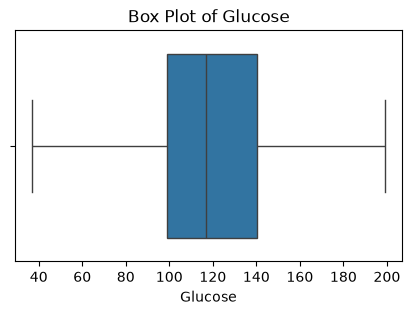

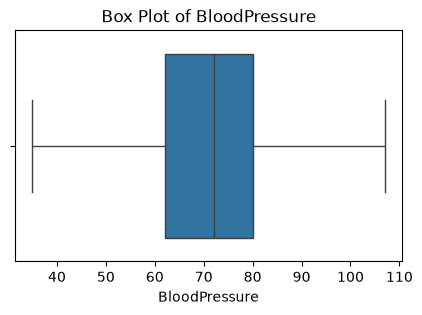

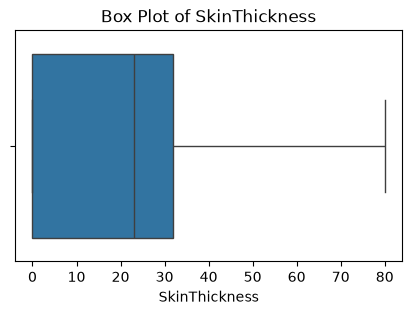

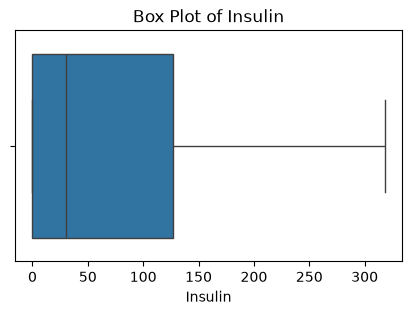

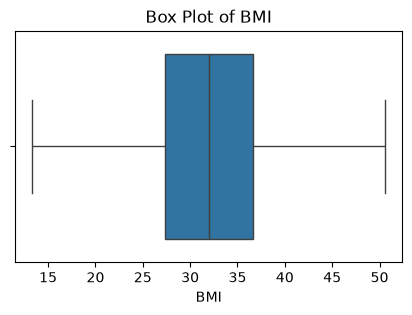

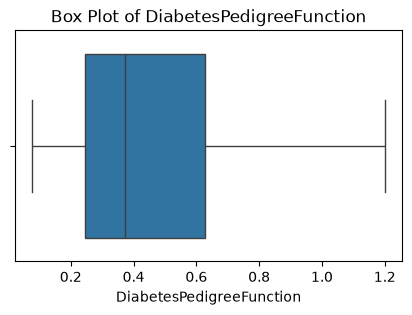

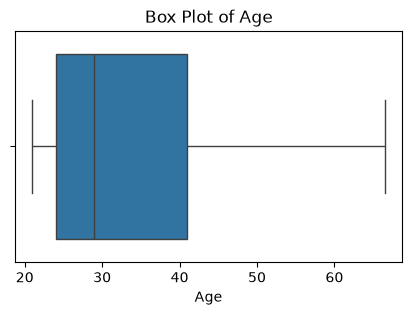

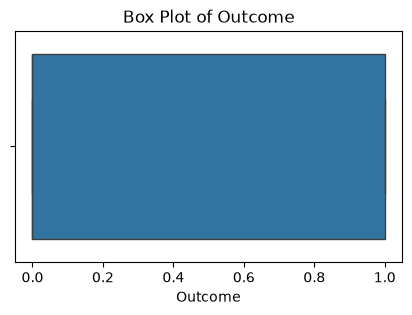

In [12]:
# Check numeric distributions after outlier capping
numeric_cols = df.select_dtypes(include="number").columns
for col in numeric_cols:
    plt.figure(figsize=(5, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Box Plot of {col}")
    plt.show()

In [13]:
X = df.drop(columns=["Outcome"])
y = df["Outcome"]

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=50, stratify=y
)

In [15]:
from sklearn.ensemble import BaggingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Note: this is a BaggingClassifier whose base estimator is Logistic Regression.
baseline_model = BaggingClassifier(
    estimator=LogisticRegression(max_iter=1000),
    n_estimators=100,
    max_samples=0.6,
    max_features=0.7,
    random_state=55,
    bootstrap_features=True
)
baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)

print("Baseline accuracy:", accuracy_score(y_test, y_pred_baseline))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_baseline))
print("Classification report:\n", classification_report(y_test, y_pred_baseline))

Baseline accuracy: 0.7402597402597403
Confusion matrix:
 [[92  8]
 [32 22]]
Classification report:
               precision    recall  f1-score   support

           0       0.74      0.92      0.82       100
           1       0.73      0.41      0.52        54

    accuracy                           0.74       154
   macro avg       0.74      0.66      0.67       154
weighted avg       0.74      0.74      0.72       154



In [16]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_samples": [0.5, 0.6, 0.7],
    "max_features": [0.5, 0.6, 0.7]
}

grid_search = GridSearchCV(
    estimator=baseline_model,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",BaggingClassi...ndom_state=55)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_features': [0.5, 0.6, ...], 'max_samples': [0.5, 0.6, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, def

In [17]:
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation accuracy:", grid_search.best_score_)

best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)
print("Tuned test accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Tuned confusion matrix:\n", confusion_matrix(y_test, y_pred_tuned))
print("Tuned classification report:\n", classification_report(y_test, y_pred_tuned))

Best parameters: {'max_features': 0.7, 'max_samples': 0.7, 'n_estimators': 200}
Best cross-validation accuracy: 0.7769025723044115
Tuned test accuracy: 0.7402597402597403
Tuned confusion matrix:
 [[93  7]
 [33 21]]
Tuned classification report:
               precision    recall  f1-score   support

           0       0.74      0.93      0.82       100
           1       0.75      0.39      0.51        54

    accuracy                           0.74       154
   macro avg       0.74      0.66      0.67       154
weighted avg       0.74      0.74      0.71       154



In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_tuned, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_tuned, zero_division=0))

Accuracy: 0.7402597402597403
Precision: 0.75
Recall: 0.3888888888888889
F1-score: 0.5121951219512195


## ROC curve and AUC

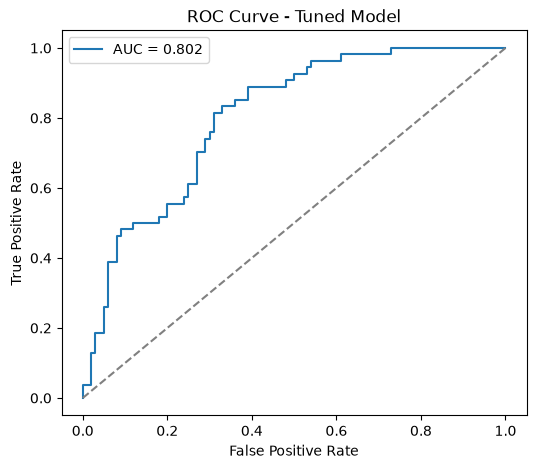

ROC-AUC: 0.8022222222222223


In [19]:
from sklearn.metrics import roc_auc_score, roc_curve

probabilities = best_model.predict_proba(X_test)[:, 1]
auc_score = roc_auc_score(y_test, probabilities)
fpr, tpr, thresholds = roc_curve(y_test, probabilities)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Model")
plt.legend()
plt.show()
print("ROC-AUC:", auc_score)

## Interpretation of Logistic Regression coefficients

The fitted model is a `BaggingClassifier` whose base estimator is `LogisticRegression`. Therefore, there is not one single coefficient vector for the full ensemble. The following cell summarizes coefficients from the Logistic Regression estimators inside the tuned bagging model. Because the original features are not standardized and some estimators use different feature subsets, treat coefficient magnitudes as approximate; focus on the average direction (positive/negative) and avoid interpreting them as causal effects. For a positive coefficient, increasing that feature tends to increase the model's log-odds of `Outcome = 1`, holding other included features constant within that base estimator.

In [20]:
# Summarize base Logistic Regression coefficients from the tuned BaggingClassifier.
# estimator_features_ maps each base estimator's coefficient positions to the original X columns.
coef_records = []
for estimator, feature_indices in zip(best_model.estimators_, best_model.estimators_features_):
    if not hasattr(estimator, "coef_"):
        continue
    for feature_idx, coef in zip(feature_indices, estimator.coef_[0]):
        coef_records.append((X.columns[int(feature_idx)], float(coef)))

coef_df = pd.DataFrame(coef_records, columns=["Feature", "Coefficient"])
coef_summary = (coef_df.groupby("Feature")["Coefficient"]
                .agg(Mean_Coefficient="mean", Mean_Absolute_Coefficient=lambda s: s.abs().mean(),
                     Estimator_Count="count")
                .sort_values("Mean_Absolute_Coefficient", ascending=False))
coef_summary

,Mean_Coefficient,Mean_Absolute_Coefficient,Estimator_Count
Feature,,,
DiabetesPedigreeFunction,0.772200,0.777589,125
Pregnancies,0.094024,0.094024,147
BMI,0.069292,0.069292,118
Glucose,0.031377,0.031377,125
Age,0.030428,0.030795,137
SkinThickness,0.001539,0.008114,119
BloodPressure,0.003712,0.008034,114
Insulin,0.000699,0.001932,115


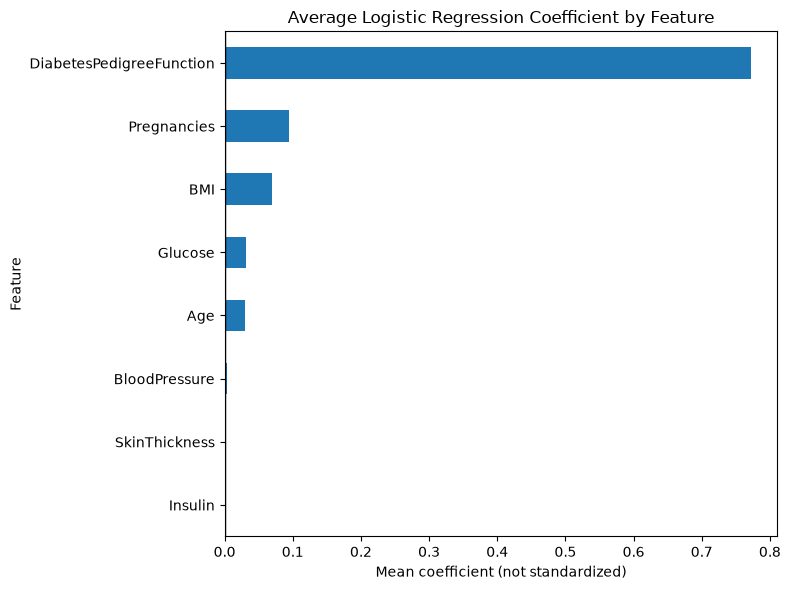

In [21]:
coef_summary["Mean_Coefficient"].sort_values().plot(kind="barh", figsize=(8, 6))
plt.axvline(0, color="black", linewidth=1)
plt.title("Average Logistic Regression Coefficient by Feature")
plt.xlabel("Mean coefficient (not standardized)")
plt.tight_layout()
plt.show()

1. What is the difference between precision and recall?

Precision measures how many of the predicted positive cases are actually positive, while Recall measures how many of the actual positive cases the model correctly identifies. Precision is important when false positives are costly, whereas Recall is important when false negatives are costly. The choice depends on the business problem.

2. What is cross-validation, and why is it important in binary classification?


Cross-validation is a model evaluation technique that estimates how well a model will generalize to unseen data. In K-Fold Cross-Validation, the dataset is split into K folds, and the model is trained K times, using a different fold for testing each time. The final performance is the average across all folds. For binary classification, Stratified K-Fold is preferred because it preserves the class distribution in every fold, leading to a more reliable evaluation, especially for imbalanced datasets.

In [22]:
import pickle

with open("logistic_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

print("Model saved successfully as logistic_model.pkl")

Model saved successfully as logistic_model.pkl


### Streamlit application code (`app.py`)

Save the following code as `app.py` in the same folder as `logistic_model.pkl`. The input order matches the dataset feature columns.

```python
import pickle
import pandas as pd
import streamlit as st

FEATURES = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"
]

@st.cache_resource
def load_model():
    with open("logistic_model.pkl", "rb") as file:
        return pickle.load(file)

model = load_model()
st.title("Diabetes Outcome Prediction")
st.write("Enter the feature values below to estimate the model's predicted class.")

with st.form("prediction_form"):
    pregnancies = st.number_input("Pregnancies", min_value=0, max_value=20, value=1, step=1)
    glucose = st.number_input("Glucose", min_value=0.0, value=120.0)
    blood_pressure = st.number_input("BloodPressure", min_value=0.0, value=70.0)
    skin_thickness = st.number_input("SkinThickness", min_value=0.0, value=20.0)
    insulin = st.number_input("Insulin", min_value=0.0, value=80.0)
    bmi = st.number_input("BMI", min_value=0.0, value=25.0)
    dpf = st.number_input("DiabetesPedigreeFunction", min_value=0.0, value=0.5)
    age = st.number_input("Age", min_value=1, max_value=120, value=30, step=1)
    submitted = st.form_submit_button("Predict")

if submitted:
    input_df = pd.DataFrame([[pregnancies, glucose, blood_pressure, skin_thickness,
                              insulin, bmi, dpf, age]], columns=FEATURES)
    prediction = int(model.predict(input_df)[0])
    st.subheader("Prediction")
    st.write("Predicted class:", prediction)
    if hasattr(model, "predict_proba"):
        probability = float(model.predict_proba(input_df)[0, 1])
        st.write(f"Model-estimated probability of Outcome = 1: {probability:.1%}")
    st.caption("This educational model is not a medical diagnosis.")
```

**Important:** This app assumes the dataset has the standard eight Pima diabetes predictor columns listed above. If your `df.columns` differ, update `FEATURES` and the matching input fields to exactly match your training columns.
